#### 4x4 Corridor Scenario (5D Bicycle model)

This notebook follows the `square_3D.ipynb` workflow and implements:
1. A `4x4` map with two rectangular obstacles matching the provided figure.
2. A Temporal Logic Tree task: avoid both obstacles until the goal region is reached.
3. Backward reachable tube (BRT) computation and export to a NumPy file.

State: `[x, y, yaw, delta, vel]` — position, heading, steering angle, speed.


In [1]:
import sys
import os
import jax

jax.config.update("jax_platform_name", "cpu")

print(jax.default_backend())
print(jax.devices())

# Add `pyspect/src` to path when running from `pyspect/hjb_mpc`.
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# src_path = os.path.join(parent_dir, "src")

src_path = "/home/veronica/Projects/pyspect/src"
if src_path not in sys.path:
    sys.path.append(src_path)

from functools import reduce
from math import pi
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from pyspect import *
from pyspect.primitives import *
from pyspect.tlt import *
from pyspect.set_builder import *

TLT.select(ContLTL)


cpu
[CpuDevice(id=0)]


/home/veronica/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1) Create the 4x4 map


In [2]:
# Map bounds: [0, 4] x [0, 4]
X0, XN = 0.0, 4.0
Y0, YN = 0.0, 4.0

dt = 0.2

# Obstacle 1: lower-left 2x2 square
lower_obs_x, lower_obs_y = 0.0, 0.0
lower_obs_w, lower_obs_h = 2.0, 2.0

# Obstacle 2: top corridor block, 2.8 long and 0.2 wide
upper_obs_x, upper_obs_y = 1.2, 2.8
upper_obs_w, upper_obs_h = 2.8, 0.4

# Goal region in the upper-right corner
goal_x, goal_y = 3.58, 3.46
goal_w, goal_h = 0.30, 0.36
target_set = BoundedSet(x=(goal_x, goal_x + goal_w), y=(goal_y, goal_y + goal_h))

# Car start: [x, y, yaw, delta, vel]
car_w, car_h = 0.25, 0.40
STATE_INIT = np.array([3.00, 0.32, pi / 2, 0.0, 0.5])
print("STATE_INIT:", STATE_INIT)

# Keep map bounds slightly inside domain
map_box = BoundedSet(x=(X0 + 0.01, X0 + XN - 0.01), y=(Y0 + 0.01, Y0 + YN - 0.01))
lower_obstacle = AND(
    AND(map_box, BoundedSet(x=(..., lower_obs_x + lower_obs_w))),
    BoundedSet(y=(..., lower_obs_y + lower_obs_h)),
)
upper_obstacle = AND(
    AND(map_box, BoundedSet(x=(upper_obs_x, ...))),
    BoundedSet(y=(upper_obs_y, upper_obs_y + upper_obs_h)),
)
obstacles = OR(lower_obstacle, upper_obstacle)

# Forward being in direction of y
_v = .3 # moving obstacle speed
_w = .4 # moving obstacle width
_x = 2.0 # moving obstacle center x
moving_obstacle_boundary = BoundedSet(x=(_x-_w/2, _x+_w/2), y=(3., ...))
moving_obstacle = EMPTY
for i, t in enumerate([0.1, 5.1, 10.1, 15.1, 19.1]):
    __v = +_v if i % 2 == 0 else -_v
    __t = t + 0.5 if i % 2 == 0 else t - 0.5
    infront_moving_obstacle = HalfSpaceSet(normal=[ +1, -__v],
                                           offset=[3.5,    t],
                                           axes = ['y',  't'])

    behind_moving_obstacle = HalfSpaceSet(normal=[ -1, +__v],
                                          offset=[3.0,  __t],
                                          axes = ['y',  't'])
    moving_obstacle = Union(moving_obstacle, reduce(Inter, [
        Compl(infront_moving_obstacle), 
        Compl(behind_moving_obstacle),
        moving_obstacle_boundary,
    ]))

# safe_region = AND(map_box, NOT(OR(obstacles, moving_obstacle)))
safe_region = AND(map_box, NOT(obstacles))

print(f"Lower obstacle: x=({lower_obs_x}, {lower_obs_x + lower_obs_w}), y=({lower_obs_y}, {lower_obs_y + lower_obs_h})")
print(f"Upper obstacle: x=({upper_obs_x}, {upper_obs_x + upper_obs_w}), y=({upper_obs_y}, {upper_obs_y + upper_obs_h})")
print(f"Goal region: x=({goal_x}, {goal_x + goal_w}), y=({goal_y}, {goal_y + goal_h})")


STATE_INIT: [3.         0.32       1.57079633 0.         0.5       ]
Lower obstacle: x=(0.0, 2.0), y=(0.0, 2.0)
Upper obstacle: x=(1.2, 4.0), y=(2.8, 3.1999999999999997)
Goal region: x=(3.58, 3.88), y=(3.46, 3.82)


/tmp/ipykernel_1123005/1162072974.py:18: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  target_set = BoundedSet(x=(goal_x, goal_x + goal_w), y=(goal_y, goal_y + goal_h))
/tmp/ipykernel_1123005/1162072974.py:26: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  map_box = BoundedSet(x=(X0 + 0.01, X0 + XN - 0.01), y=(Y0 + 0.01, Y0 + YN - 0.01))
/tmp/ipykernel_1123005/1162072974.py:28: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  AND(map_box, BoundedSet(x=(..., lower_obs_x + lower_obs_w))),
/tmp/ipykernel_1123005/1162072974.py:29: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use Align

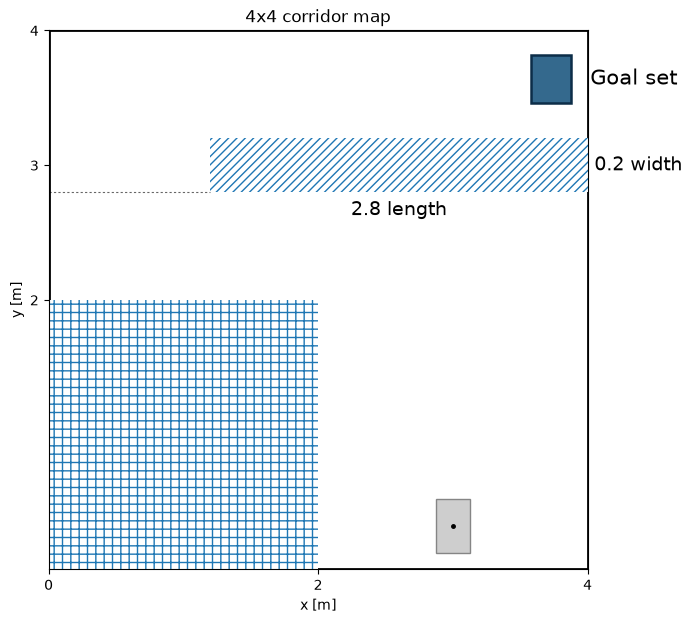

In [3]:
from matplotlib.patches import Rectangle
from matplotlib.transforms import Affine2D

fig, ax = plt.subplots(figsize=(7, 7))

# Workspace square
ax.add_patch(Rectangle((X0, Y0), XN, YN, fill=False, lw=2, edgecolor="black"))

# Obstacles
ax.add_patch(Rectangle((lower_obs_x, lower_obs_y), lower_obs_w, lower_obs_h, facecolor="white", edgecolor="tab:blue", hatch="++", linewidth=0.0, label="Obstacle"))
ax.add_patch(Rectangle((upper_obs_x, upper_obs_y), upper_obs_w, upper_obs_h, facecolor="white", edgecolor="tab:blue", hatch="////", linewidth=0.0))

# Goal set
ax.add_patch(Rectangle((goal_x, goal_y), goal_w, goal_h, facecolor="#34698d", edgecolor="#0c2d48", linewidth=1.8, label="Goal set"))

# Car pose
heading_deg = np.degrees(STATE_INIT[2])
car_rect = Rectangle((-car_h / 2, -car_w / 2), car_h, car_w, facecolor="0.8", edgecolor="0.5", alpha=0.95, linewidth=1.0, label="Car")
t = Affine2D().rotate_deg(heading_deg).translate(STATE_INIT[0], STATE_INIT[1]) + ax.transData
car_rect.set_transform(t)
ax.add_patch(car_rect)
ax.plot(STATE_INIT[0], STATE_INIT[1], "ko", markersize=2.5)

# Figure annotations
ax.hlines(upper_obs_y, X0, upper_obs_x, colors="k", linestyles=(0, (2, 2)), linewidth=0.8, alpha=0.6)
ax.text(upper_obs_x + upper_obs_w / 2, upper_obs_y - 0.06, "2.8 length", ha="center", va="top", fontsize=14)
ax.text(upper_obs_x + upper_obs_w + 0.05, upper_obs_y + upper_obs_h / 2, "0.2 width", ha="left", va="center", fontsize=14)
ax.text(goal_x + goal_w + 0.14, goal_y + goal_h / 2, "Goal set", ha="left", va="center", fontsize=15)

ax.set_xlim(X0, X0 + XN)
ax.set_ylim(Y0, Y0 + YN)
ax.set_aspect("equal", adjustable="box")
ax.set_title("4x4 corridor map")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_xticks([0, 2, 4])
ax.set_yticks([2, 3, 4])
ax.grid(False)
plt.show()


## 2) Specify the task in Temporal Logic Tree form

In [4]:
def FollowTo(constraint, goal_or_constraint, *more):
    if more: # 2nd arg is constraint
        return FollowTo(And(constraint, goal_or_constraint), *more)
    else: # 2nd arg is exit
        return Until(constraint, goal_or_constraint)

vehicle_1 = UNTIL(safe_region, target_set)
# print(vehicle_1)

## 3) Compute the BRT using TVHJImpl

In [5]:
from pyspect.systems.hj_reachability.bicycle4d import Bicycle4D
from pyspect.impls.hj_reachability import TVHJImpl
from pyspect.plotting.levelsets import plot3D_levelset

jax.config.update("jax_platform_name", "cpu")

t_max = 20

# Steering limits [rad] and acceleration limits [m/s²]
max_steer = 0.7
max_steer_rate = np.pi
max_accel = 0.4
max_vel   = 0.8

impl = TVHJImpl(
    dynamics=dict(
        cls=Bicycle4D,
        min_steer=-max_steer,
        max_steer=max_steer,
        min_accel=-max_accel,
        max_accel=max_accel,
        wheelbase=0.32,
    ),
    axis_specs=[
        dict(name='t',      bounds=[0, t_max],           points=101),
        dict(name='x',      bounds=[X0, X0 + XN],        points=25),
        dict(name='y',      bounds=[Y0, Y0 + YN],        points=25),
        dict(name='*yaw',   bounds=[-pi, pi],             points=15),
        dict(name='vel',    bounds=[0.0, max_vel],        points=11),
    ],
)

In [6]:
print(jax.default_backend())
print(jax.devices())

out1 = TLT.construct(vehicle_1).realize(impl)
print("BRT shape:", out1.shape)

np.save("out_bicycle5d.npy", np.asarray(out1))
print("Saved")


cpu
[CpuDevice(id=0)]


Running for 100 iterations:   0%|          | 0/100 [00:00<?, ?it/s]

BRT shape: (101, 25, 25, 15, 11)
Saved



--- RESULTS ---
Crop idx: 41 over 100
t_max: 8.20 s
Necessary time: 11.80 s


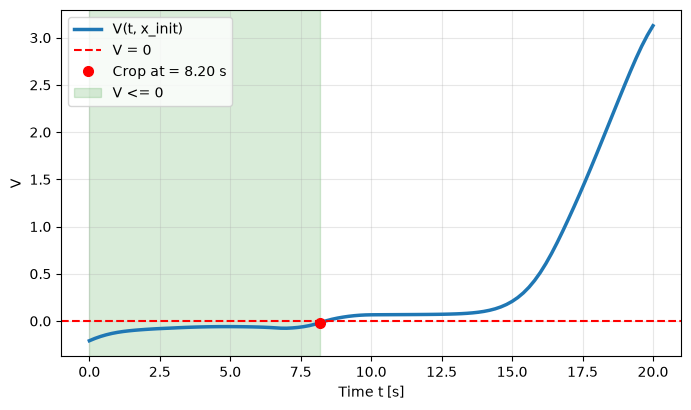

In [7]:
import numpy as np
import matplotlib.pyplot as plt

x_init   = STATE_INIT[0]
y_init   = STATE_INIT[1]
yaw_init = STATE_INIT[2]
vel_init = STATE_INIT[4] if len(STATE_INIT) > 4 else STATE_INIT[3]

x_coords   = np.array(impl.grid.coordinate_vectors[0])
y_coords   = np.array(impl.grid.coordinate_vectors[1])
yaw_coords = np.array(impl.grid.coordinate_vectors[2])
vel_coords = np.array(impl.grid.coordinate_vectors[3])

ix   = int(np.argmin(np.abs(x_coords - x_init)))
iy   = int(np.argmin(np.abs(y_coords - y_init)))
iyaw = int(np.argmin(np.abs(yaw_coords - yaw_init)))
ivel = int(np.argmin(np.abs(vel_coords - vel_init)))

time_grid = np.array(impl.timeline)

v_time_profile = np.array(out1[:, ix, iy, iyaw, ivel])
safe_indices = np.where(v_time_profile <= 0.0)[0]

if len(safe_indices) == 0:
    print("ERROR: Lo stato iniziale non raggiunge il goal per nessun istante.")
else:
    safety_frames = 0
    idx_max = max(0, safe_indices[-1] - safety_frames)
    t_max = time_grid[idx_max]
    delta_t_min = time_grid[-1] - t_max
    
    print("\n--- RESULTS ---")
    print(f"Crop idx: {idx_max} over {len(time_grid) - 1}")
    print(f"t_max: {t_max:.2f} s")
    print(f"Necessary time: {delta_t_min:.2f} s")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(time_grid, v_time_profile, color="tab:blue", lw=2.5, label="V(t, x_init)")
ax.axhline(0.0, color="red", linestyle="--", label="V = 0 ")

if len(safe_indices) > 0:
    ax.plot(t_max, v_time_profile[idx_max], "ro", markersize=7, label=f"Crop at = {t_max:.2f} s")
    ax.axvspan(time_grid[0], t_max, color="green", alpha=0.15, label="V <= 0")

ax.set_xlabel("Time t [s]")
ax.set_ylabel("V")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

In [8]:
if len(safe_indices) > 0:
    out1_shifted = out1[idx_max:, ...]
    
    duration = time_grid[-1] - t_max
    new_timeline = np.linspace(0.0, duration, out1_shifted.shape[0])
    
    print(f"Original size of out1: {out1.shape}")
    print(f"New size of out1_shifted: {out1_shifted.shape}")
    print(f"New time interval: from {new_timeline[0]:.2f}s to {new_timeline[-1]:.2f}s")
    out1_orig = out1
    out1 = out1_shifted

Original size of out1: (101, 25, 25, 15, 11)
New size of out1_shifted: (60, 25, 25, 15, 11)
New time interval: from 0.00s to 11.80s


In [9]:
impl.plot(
    out1.sum(axis=0, keepdims=True),
    method='surface',
    axes=('x', 'y'),
    transform_select=[('t', 0.0)],
)

In [10]:
impl.plot(
    out1_orig, 
    axes=('x', 'y', 't'),
    # transform_select=[('x', 2.), ('y', 2.2)],
)

In [11]:
impl.plot(obs := moving_obstacle(impl), axes=('x', 'y', 't'), colorscale='reds').show()
print(obs.min(), obs.max())

-0.20000005 3.0


In [12]:
print(out1_orig.shape)
print(out1.shape)

(101, 25, 25, 15, 11)
(60, 25, 25, 15, 11)
